# Comparing Different Search Strategies: Maze

Notes on breaking ties: 

* The order in which the children are explored (see `available directions`) makes a big difference for DFS and dealing with empty spaces. I explore the directions in random order which makes the algorithm stochastic!
* Ties for $h(n)$ and $f(n)$ need to be broken in a consistent manner. I use the most recently added node. To try to keep moving into the same direction.



Position(0,0): X
Position(8,1):  


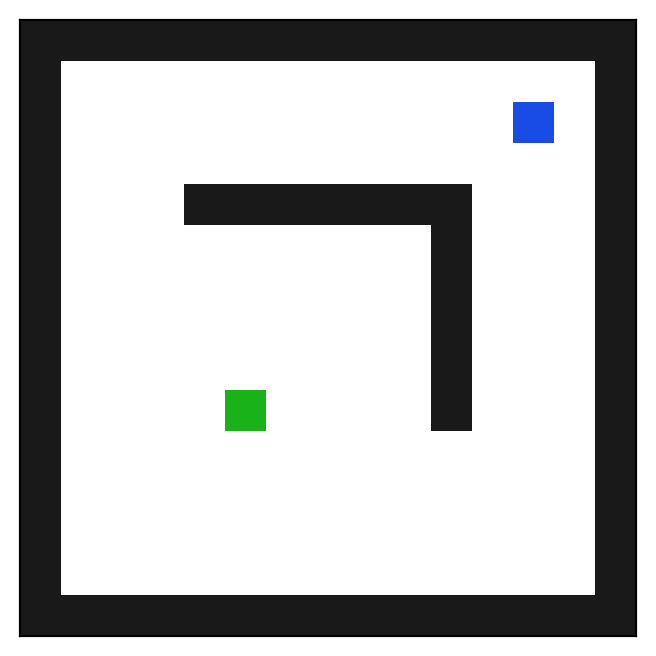

In [1]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np

#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
f = open("L_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

# look at two positions in the maze
print("Position(0,0):", maze[0, 0])
print("Position(8,1):", maze[8, 1])

show_maze(maze)

## Implementation

My implementation follows the pseudo code from the slides/textbook.

In [2]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts


# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)

## Experiments

### BFS

CPU times: user 440 μs, sys: 5 μs, total: 445 μs
Wall time: 457 μs


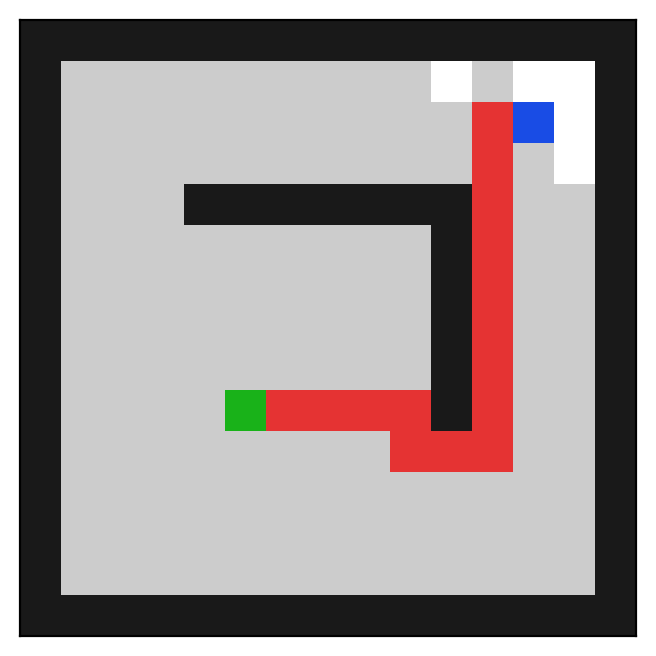

['E',
 'E',
 'E',
 'E',
 'S',
 'E',
 'E',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'E']

In [3]:
ts.set_order("NESW")
#ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "BFS", debug = False, vis = False)
ts.show_path(maze, result)
result['actions']

### DFS 

This implementation uses not reached data structure and has space complexity $O(bm)$ instead of $O(b^m)$ when we reuse the tree search algorithm from BFS!

We need to check for all cycles. If we do not break all cycles correctly, then we will end up in an infinite loop. Here are possible solutions:
* Stop after a fixed number of tries and return no solution `max_tries`.
* IDS solves this problem.

Note on the visualization: I use gray for areas that the algorithm has explored, but DFS has already removed it from memory!

CPU times: user 264 μs, sys: 0 ns, total: 264 μs
Wall time: 268 μs


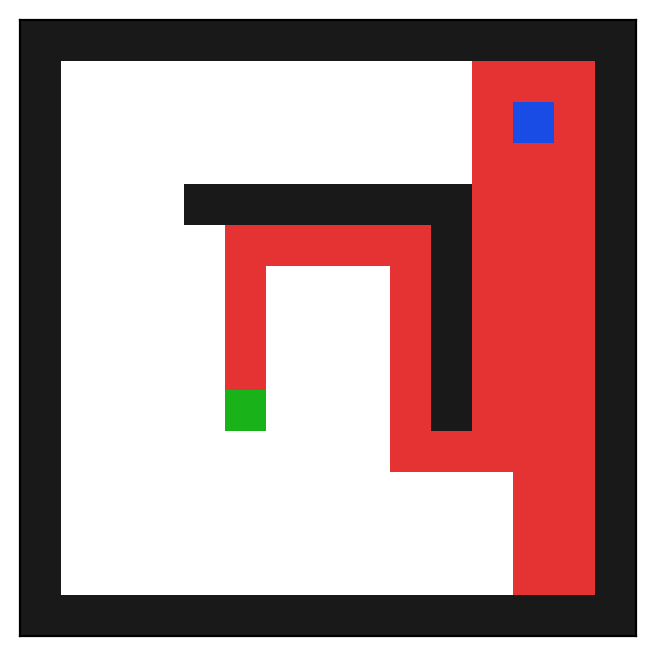

In [4]:
# Note: DFS uses LIFO so the directions come from the stack in reverse order!

# Can get stuck for empty maze since cycle checking is not string enough! 
# I use a maximum number of tries and stop if the goal is not reached.
ts.set_order("NESW")
#ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 5000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

Do the same, but change the order in which we explore states (add them to them as nodes to the frontier).

CPU times: user 151 μs, sys: 3 μs, total: 154 μs
Wall time: 156 μs


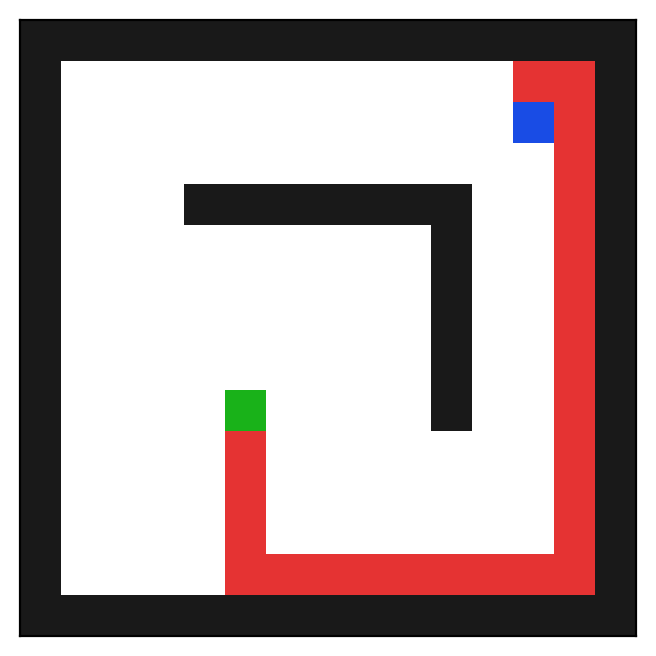

In [5]:
#ts.set_order("NESW")
ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 5000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

We could do a random walk and not check for cycles. This is guaranteed to reach eventually any square including the goal, 
but creates a long path. The path could be simplified leading to the [Tremaux's algorithm](https://en.wikipedia.org/wiki/Maze_solving_algorithm).

CPU times: user 5.19 ms, sys: 138 μs, total: 5.32 ms
Wall time: 5.33 ms


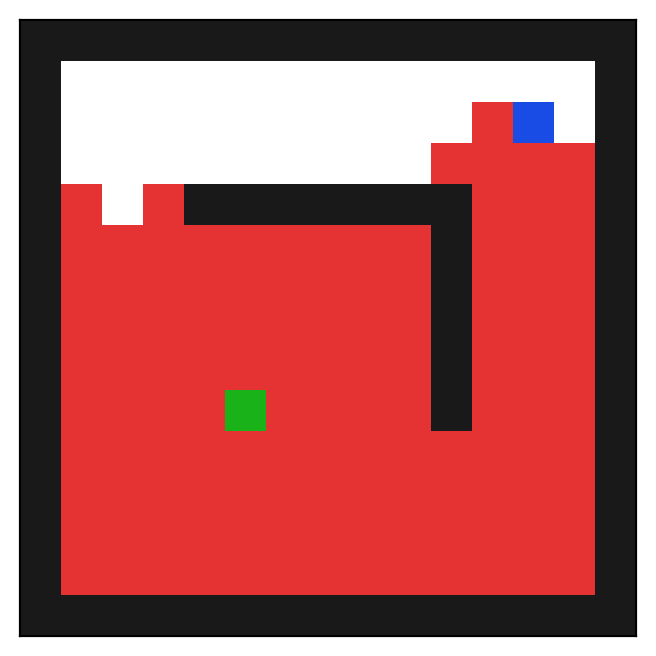

CPU times: user 2.37 ms, sys: 44 μs, total: 2.42 ms
Wall time: 2.47 ms


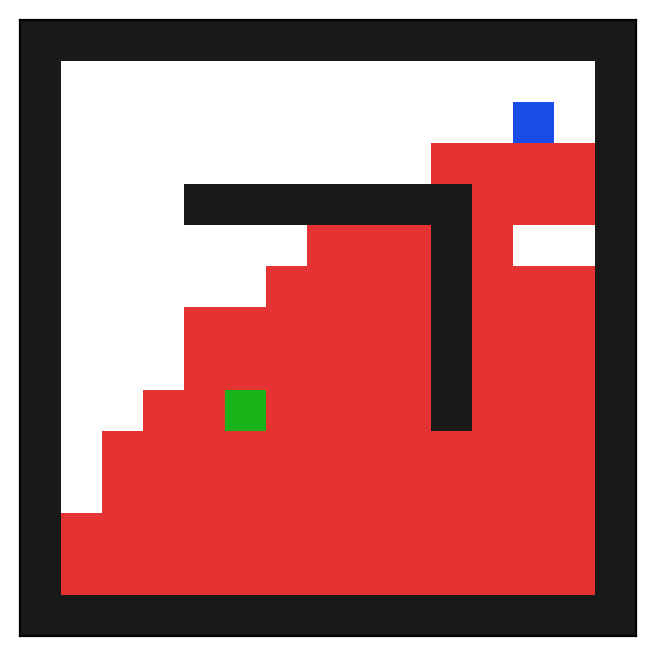

CPU times: user 7.3 ms, sys: 217 μs, total: 7.52 ms
Wall time: 8.4 ms
No solution found!


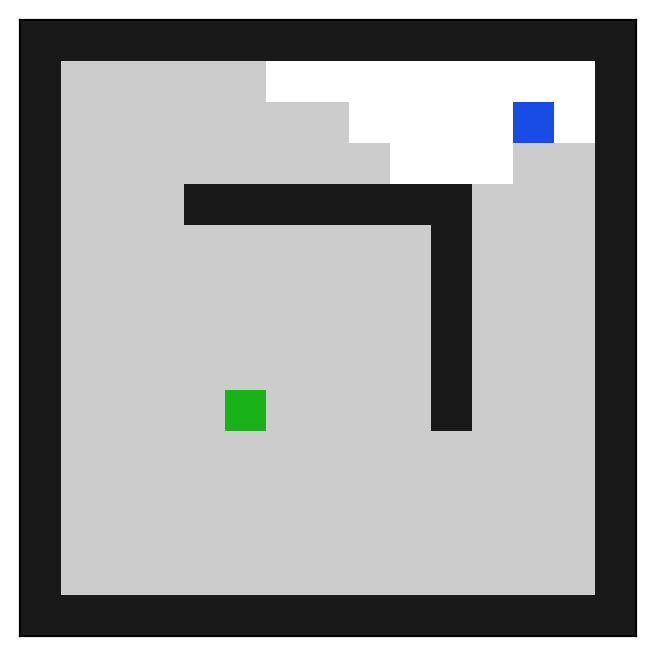

No solution found!
CPU times: user 5.94 ms, sys: 34 μs, total: 5.98 ms
Wall time: 5.98 ms
No solution found!


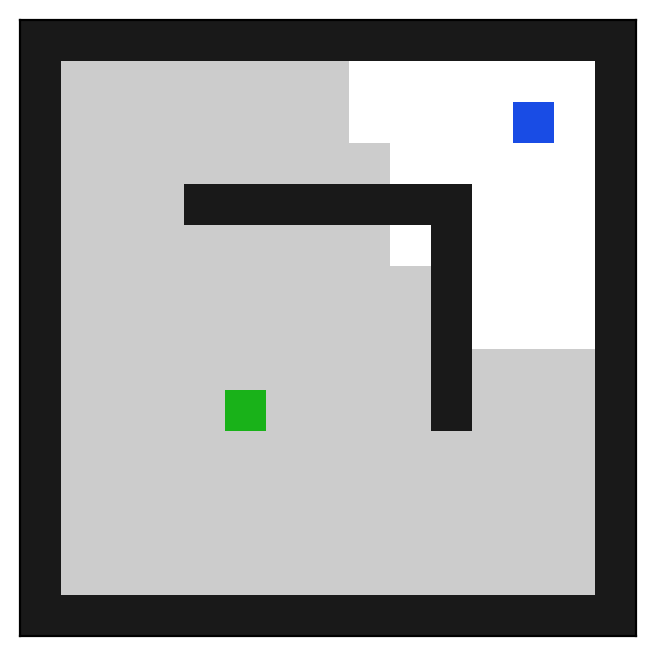

No solution found!
CPU times: user 3.26 ms, sys: 44 μs, total: 3.3 ms
Wall time: 3.3 ms


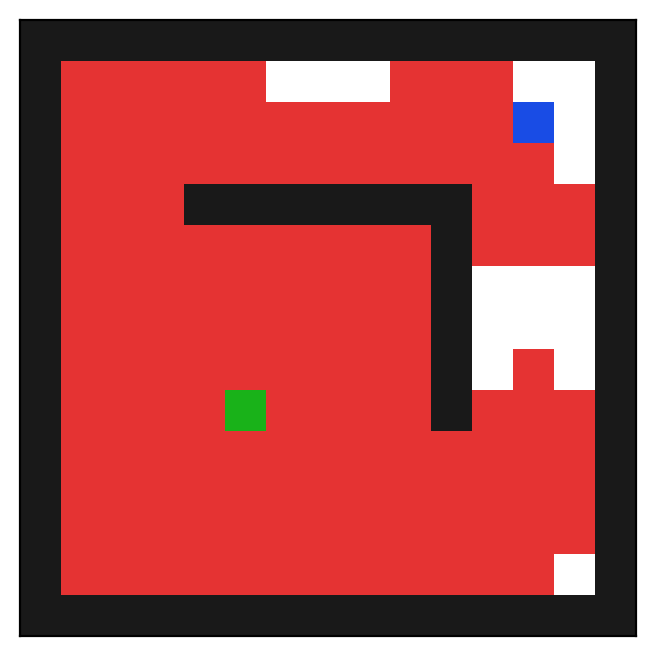

In [6]:
ts.set_order(random = True)

# run it multiple times to see the effect of randomization
import random
random.seed(20261009)
for _ in range(5):
    %time result = ts.DFS(maze, check_cycle = False, max_tries = 1500, vis = False, debug_reached = True)

    #result
    ts.show_path(maze, result)
    if result['path'] is None:
        print("No solution found!")

### Run randomized DFS multiple times and use the best solution.

__Note:__ IDS takes a similar amount of time and memory, but is guaranteed optimal.

CPU times: user 98.5 ms, sys: 879 μs, total: 99.4 ms
Wall time: 101 ms
Solutions have path_lengths of [94, 86, 76, 48, 70, 48, 72, 74]


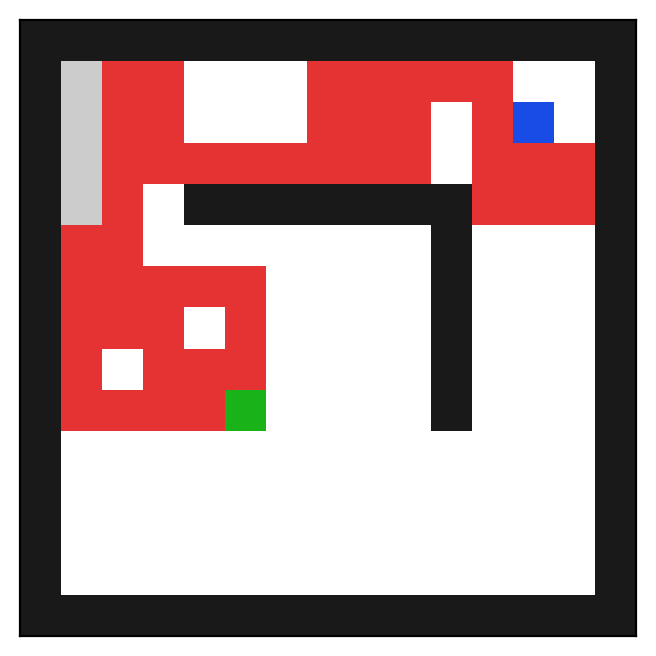

In [7]:
ts.set_order(random = True)

import random
random.seed(20261009)
N = 12
%time results = [ ts.DFS(maze, max_tries = 3000, vis = False) for _ in range(N) ]

# check if we found a solution and display the best solution
results = [ r for r in results if not r['path'] is None ]
if len(results) > 0:
    path_lengths = [ len(r['path'])-1 for r in results ]

    print(f"Solutions have path_lengths of {path_lengths}")

    result = results[ts.min_index(path_lengths)]
    ts.show_path(maze, result)
else:
    print("No solution found!")

### Depth limited DFS

Note: The frontier needs to be checked differently during cycle checking!

CPU times: user 731 μs, sys: 0 ns, total: 731 μs
Wall time: 734 μs
No solution found!


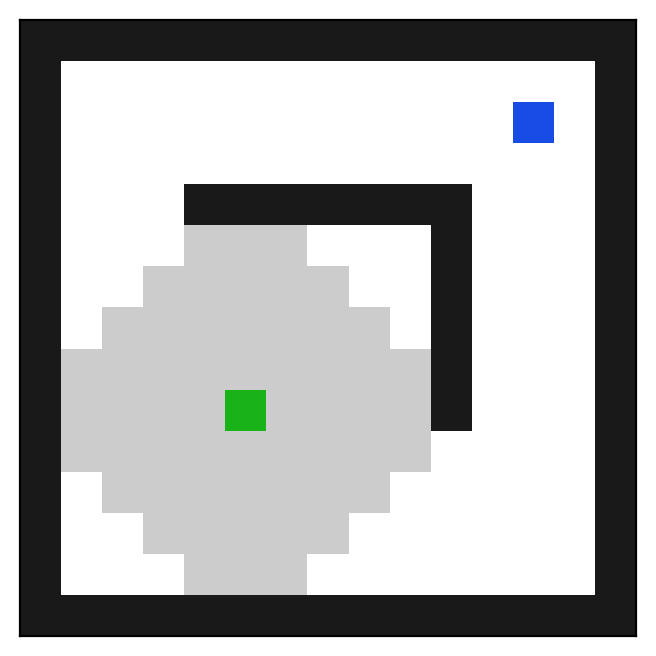

In [8]:
ts.set_order(random = True)

%time result = ts.DFS(maze, limit = 5, frontier_option = 2, max_tries = 100000, vis = False, debug_reached = True)
ts.show_path(maze, result)

### IDS

__Notes:__ 

* IDS with DFS does not store reached squares, so gray areas are not shown!

* IDS depends on the cycle checking of DFS and therefore is also affected by these problems.

CPU times: user 1.56 s, sys: 14 ms, total: 1.57 s
Wall time: 1.65 s


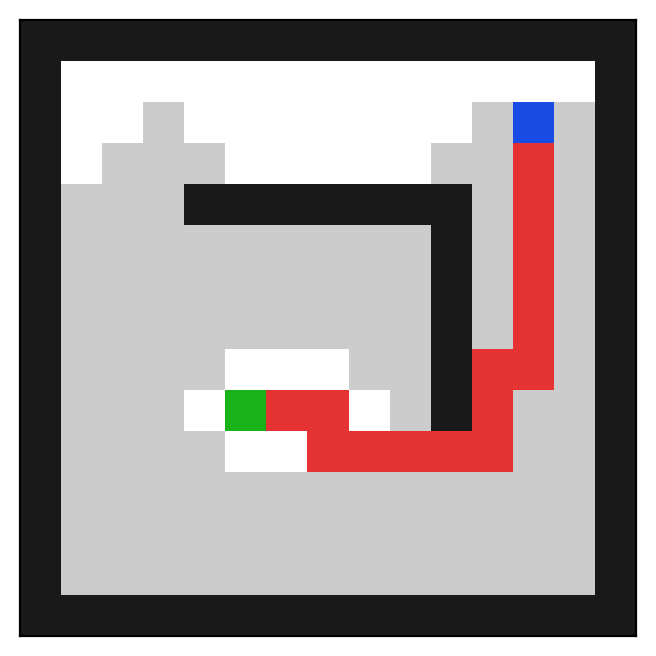

In [9]:
ts.set_order(random = True)

%time result = ts.IDS(maze, frontier_option = 2, max_tries = 100000)
ts.show_path(maze, result)

### Greedy Best-First Search (GBFS)

In [10]:
# set the heuristic to Manhattan distance
ts.heuristic = ts.manhattan

CPU times: user 640 μs, sys: 0 ns, total: 640 μs
Wall time: 643 μs


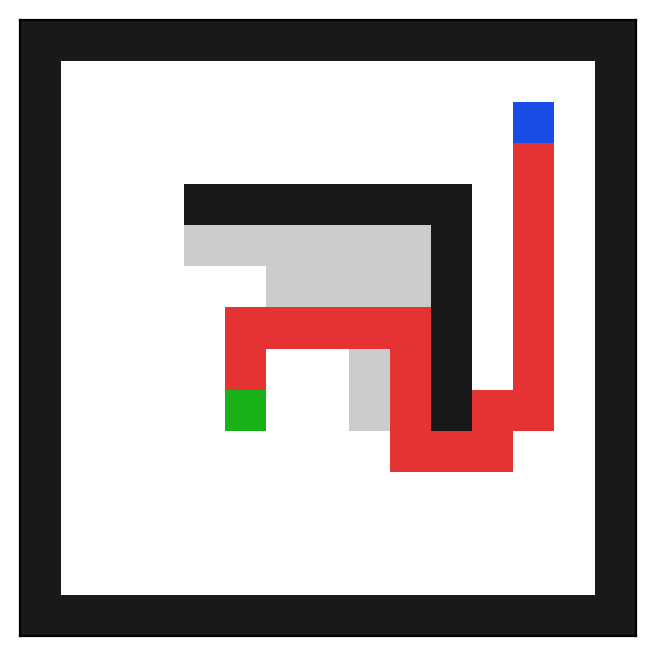

In [11]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "GBFS", debug = False, vis = False)
ts.show_path(maze, result)

### A* Search

CPU times: user 312 μs, sys: 16 μs, total: 328 μs
Wall time: 371 μs


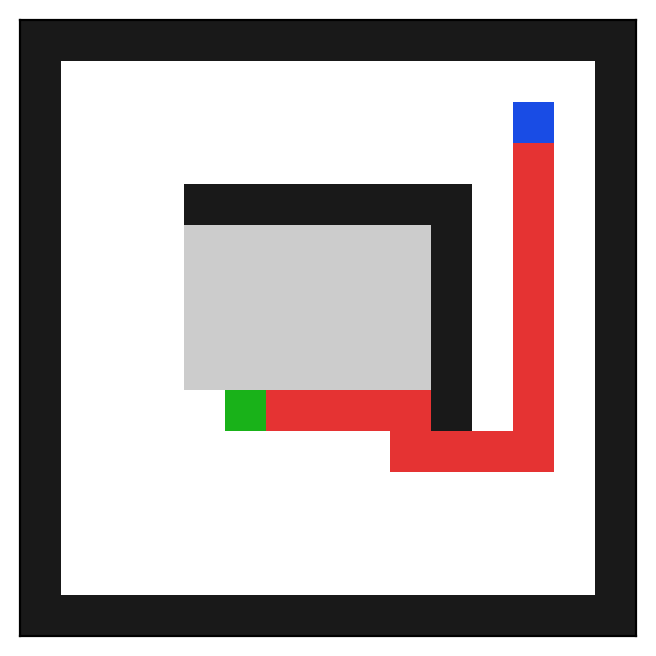

In [12]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", debug = False, vis = False)
ts.show_path(maze, result)

### Weighted A* Search

$W > 1$ tends towards GBFS (optimality is not guaranteed)

CPU times: user 263 μs, sys: 0 ns, total: 263 μs
Wall time: 265 μs


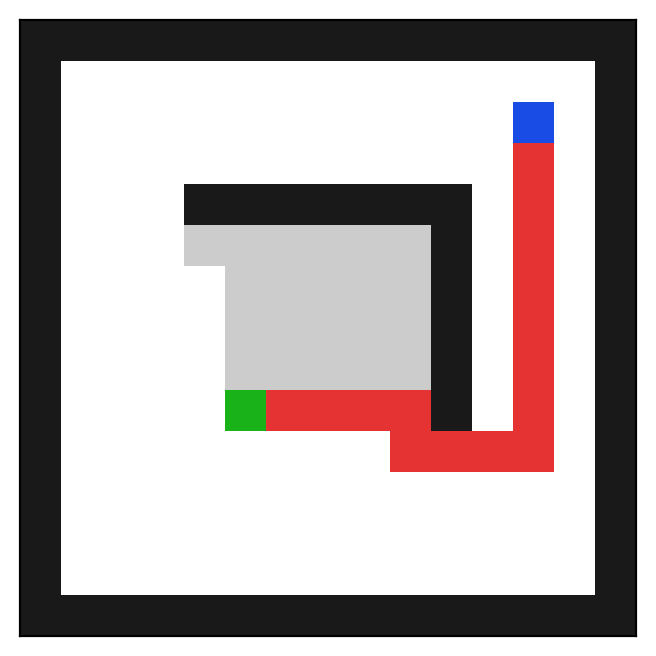

In [13]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", W = 1+1e-9, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: user 281 μs, sys: 1 μs, total: 282 μs
Wall time: 283 μs


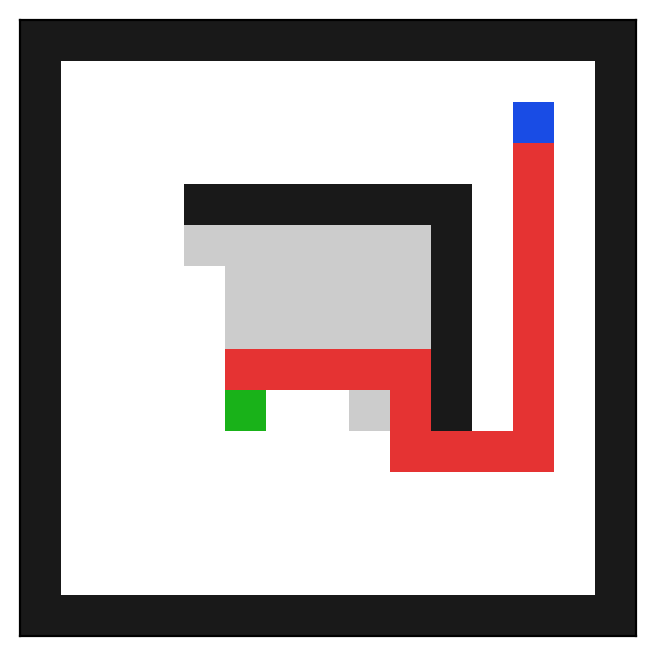

In [14]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 5, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: user 235 μs, sys: 1e+03 ns, total: 236 μs
Wall time: 237 μs


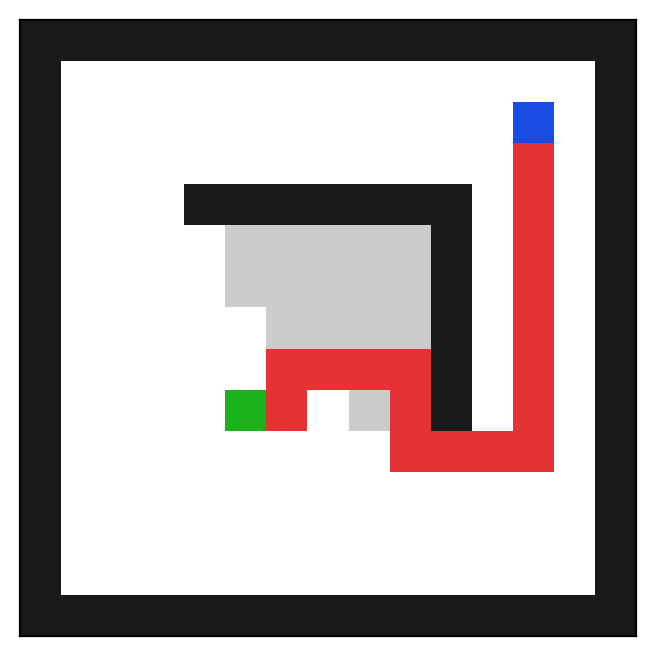

In [15]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 1000, debug = False, vis = False)
ts.show_path(maze, result)

$W<1$ tends towards Uniform-Cost Search/BFS (optimality is guaranteed)

CPU times: user 387 μs, sys: 1 μs, total: 388 μs
Wall time: 389 μs


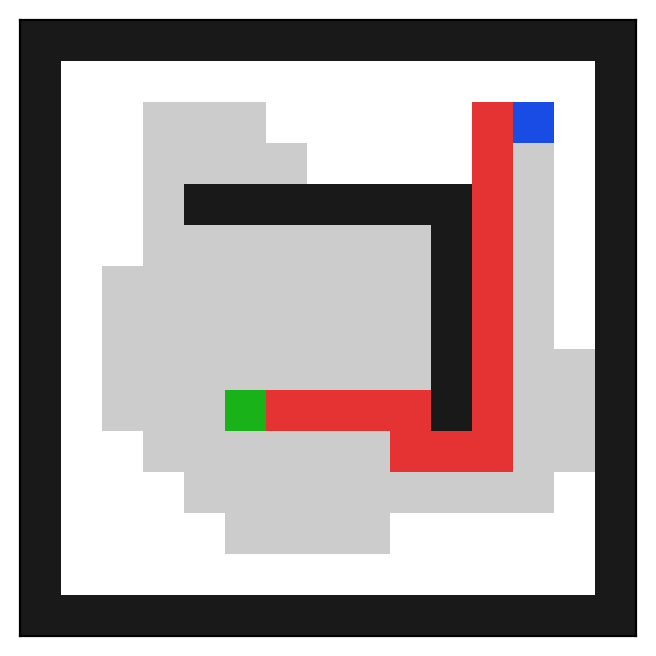

In [16]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .7, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: user 706 μs, sys: 20 μs, total: 726 μs
Wall time: 786 μs


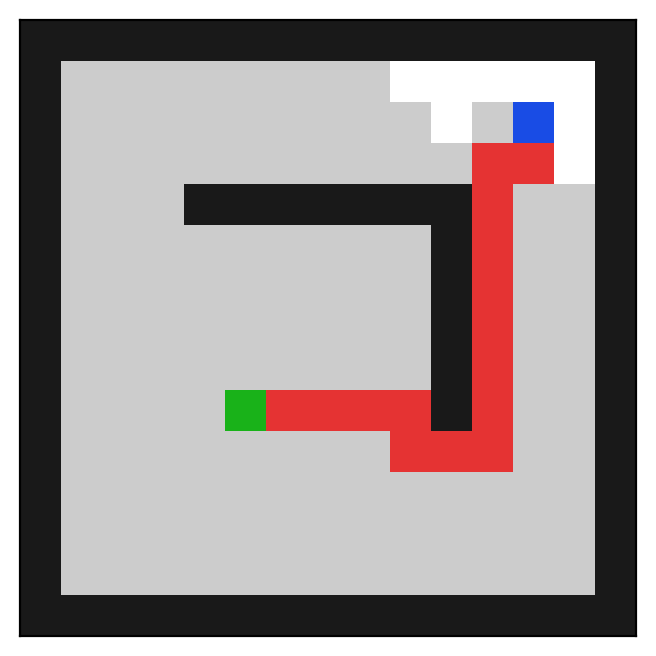

In [17]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .0001, debug = False, vis = False)
ts.show_path(maze, result)

### Compare Timing

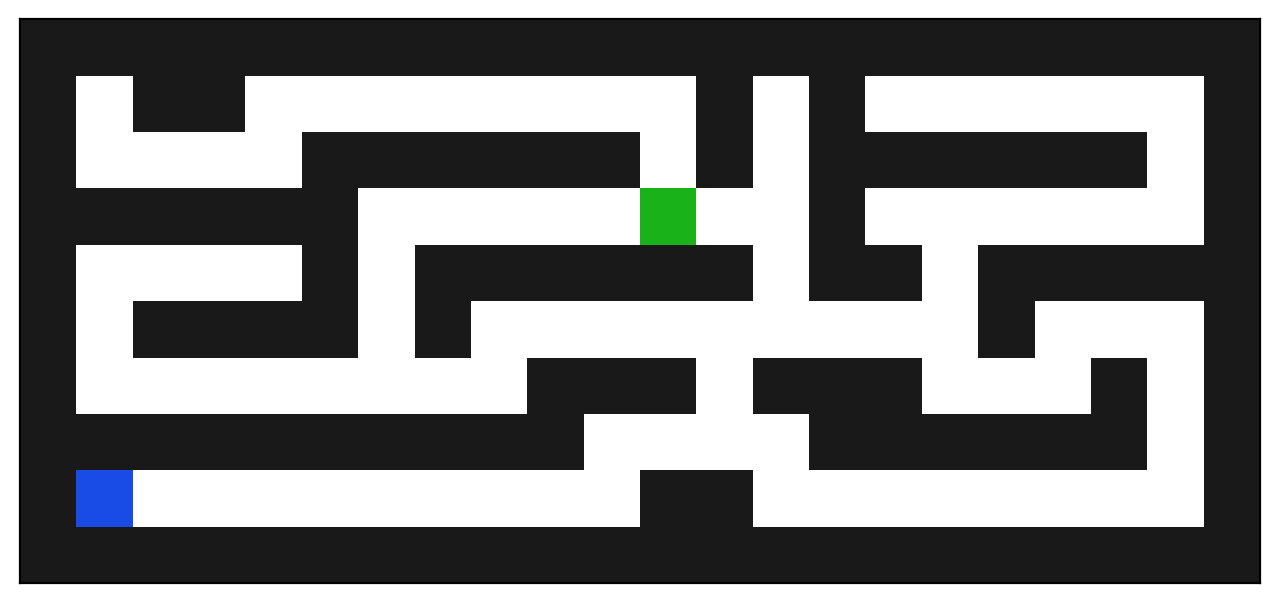

Timing: small_maze, NESW, fixed tie policy


In [18]:
from pathlib import Path
maze = parse_maze(Path('small_maze.txt').read_text())
ts.show_maze(maze)
ts.set_order('NESW',random=False)
print('Timing: small_maze, NESW, fixed tie policy')

In [19]:
# Correct: DFS must call DFS(), not best_first_search(... strategy='DFS')
import timeit
reps=3
ts.set_order('NESW',random=False)
ts.heuristic=ts.manhattan
measure = {
 'BFS':lambda:ts.best_first_search(maze,strategy='BFS'),
 'DFS':lambda:ts.DFS(maze,frontier_option=2,max_tries=5000),
 'GBFS':lambda:ts.best_first_search(maze,strategy='GBFS'),
 'A*':lambda:ts.best_first_search(maze,strategy='A*'),
 'IDS':lambda:ts.IDS(maze,frontier_option=2,max_tries=5000),
}
times={k:round(timeit.timeit(f,number=reps)*1e6/reps,1) for k,f in measure.items()}
print('microseconds / run:',times)

microseconds / run: {'BFS': 717.1, 'DFS': 269.7, 'GBFS': 115.9, 'A*': 145.9, 'IDS': 2668.9}


In [20]:
import pandas as pd
df = pd.DataFrame(times, index = ["time in micro seconds"])
df

,BFS,DFS,GBFS,A*,IDS
time in micro seconds,717.1,269.7,115.9,145.9,2668.9


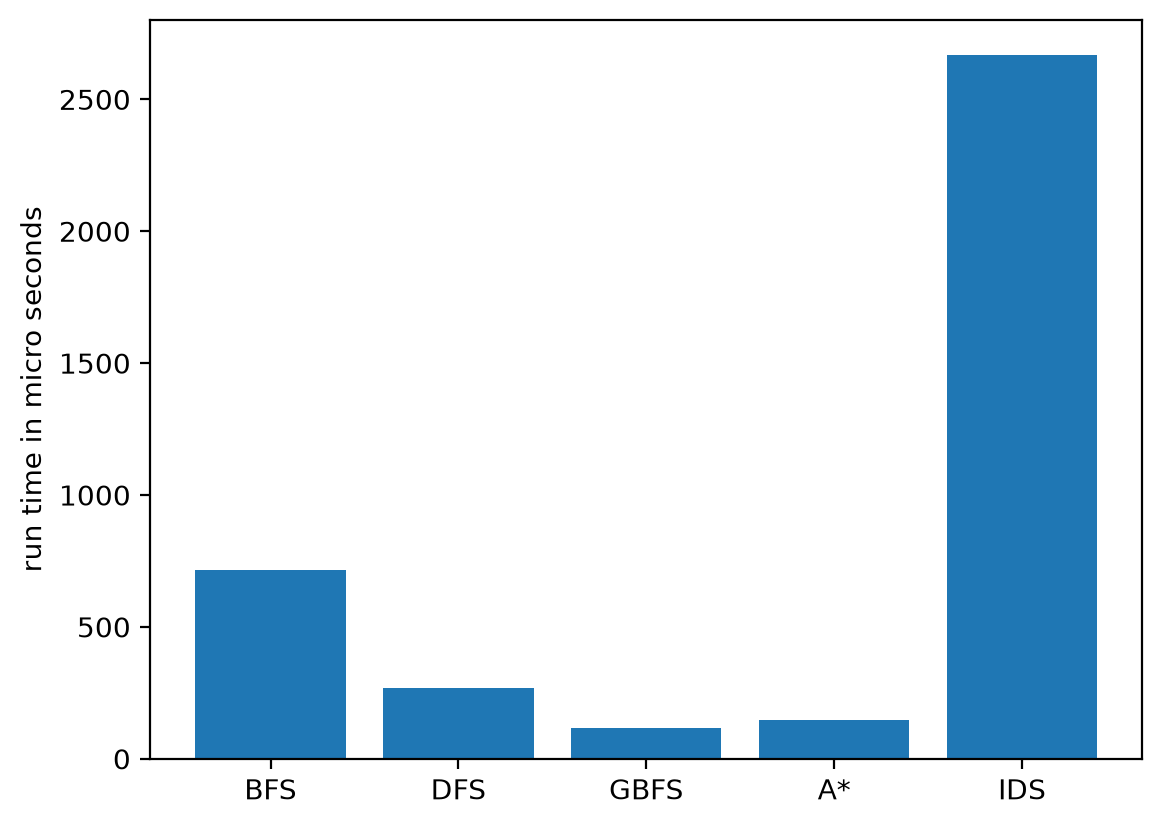

In [21]:
import matplotlib.pyplot as plt

plt.bar(df.columns, height = df.iloc[0])
plt.ylabel("run time in micro seconds")
plt.show()

## Bài 3 – Thực nghiệm BFS và DFS đã kiểm chứng
So sánh trên small, medium, open. BFS dùng FIFO, DFS dùng LIFO. Cấu hình: NESW cố định, DFS frontier_option=2, max_tries=5000. Module tree_search_solution.py đếm cả lượt lấy nút đích trong Expanded. Các khung hình được vẽ trực tiếp từ kết quả chạy, không phải hình minh họa giả định.

In [22]:
from pathlib import Path
import pandas as pd
import maze_helper as mh
import tree_search_solution as ts
from IPython.display import display
ts.set_order('NESW',random=False)
ts.heuristic=ts.manhattan
records=[];cases={}
for maze_name in ['small','medium','open']:
    arr=mh.parse_maze(Path(maze_name+'_maze.txt').read_text())
    start,goal=mh.find_pos(arr,'S'),mh.find_pos(arr,'G')
    for algorithm in ['BFS','DFS']:
        res=ts.best_first_search(arr,strategy='BFS') if algorithm=='BFS' else ts.DFS(arr,frontier_option=2,max_tries=5000)
        if res['path'] is not None:
            assert res['path'][0]==start and res['path'][-1]==goal
            assert len(res['path'])-1==res['cost']
            assert all(abs(a[0]-b[0])+abs(a[1]-b[1])==1 for a,b in zip(res['path'],res['path'][1:]))
            assert all(arr[r,c]!='X' for r,c in res['path'])
        records.append({'Maze':maze_name,'Algorithm':algorithm,'Cost':res['cost'],
          'Expanded':res['expanded'],'Max depth':res['max_depth'],
          'Max frontier':res['max_frontier'],'Time ms':round(res['time']*1000,3)})
        cases[(maze_name,algorithm)]=(arr,res)
bai3_table=pd.DataFrame(records)
display(bai3_table)
bai3_table.to_csv('lab02_bai3_bfs_dfs_verified.csv',index=False)
print('PASS - paths valid, CSV saved')

,Maze,Algorithm,Cost,Expanded,Max depth,Max frontier,Time ms
0,small,BFS,19,93,19,9,0.175
1,small,DFS,37,69,37,5,0.360
2,medium,BFS,68,270,68,9,0.456
3,medium,DFS,244,263,244,13,1.545
4,open,BFS,54,683,54,25,1.343
5,open,DFS,292,294,292,234,3.987


PASS - paths valid, CSV saved


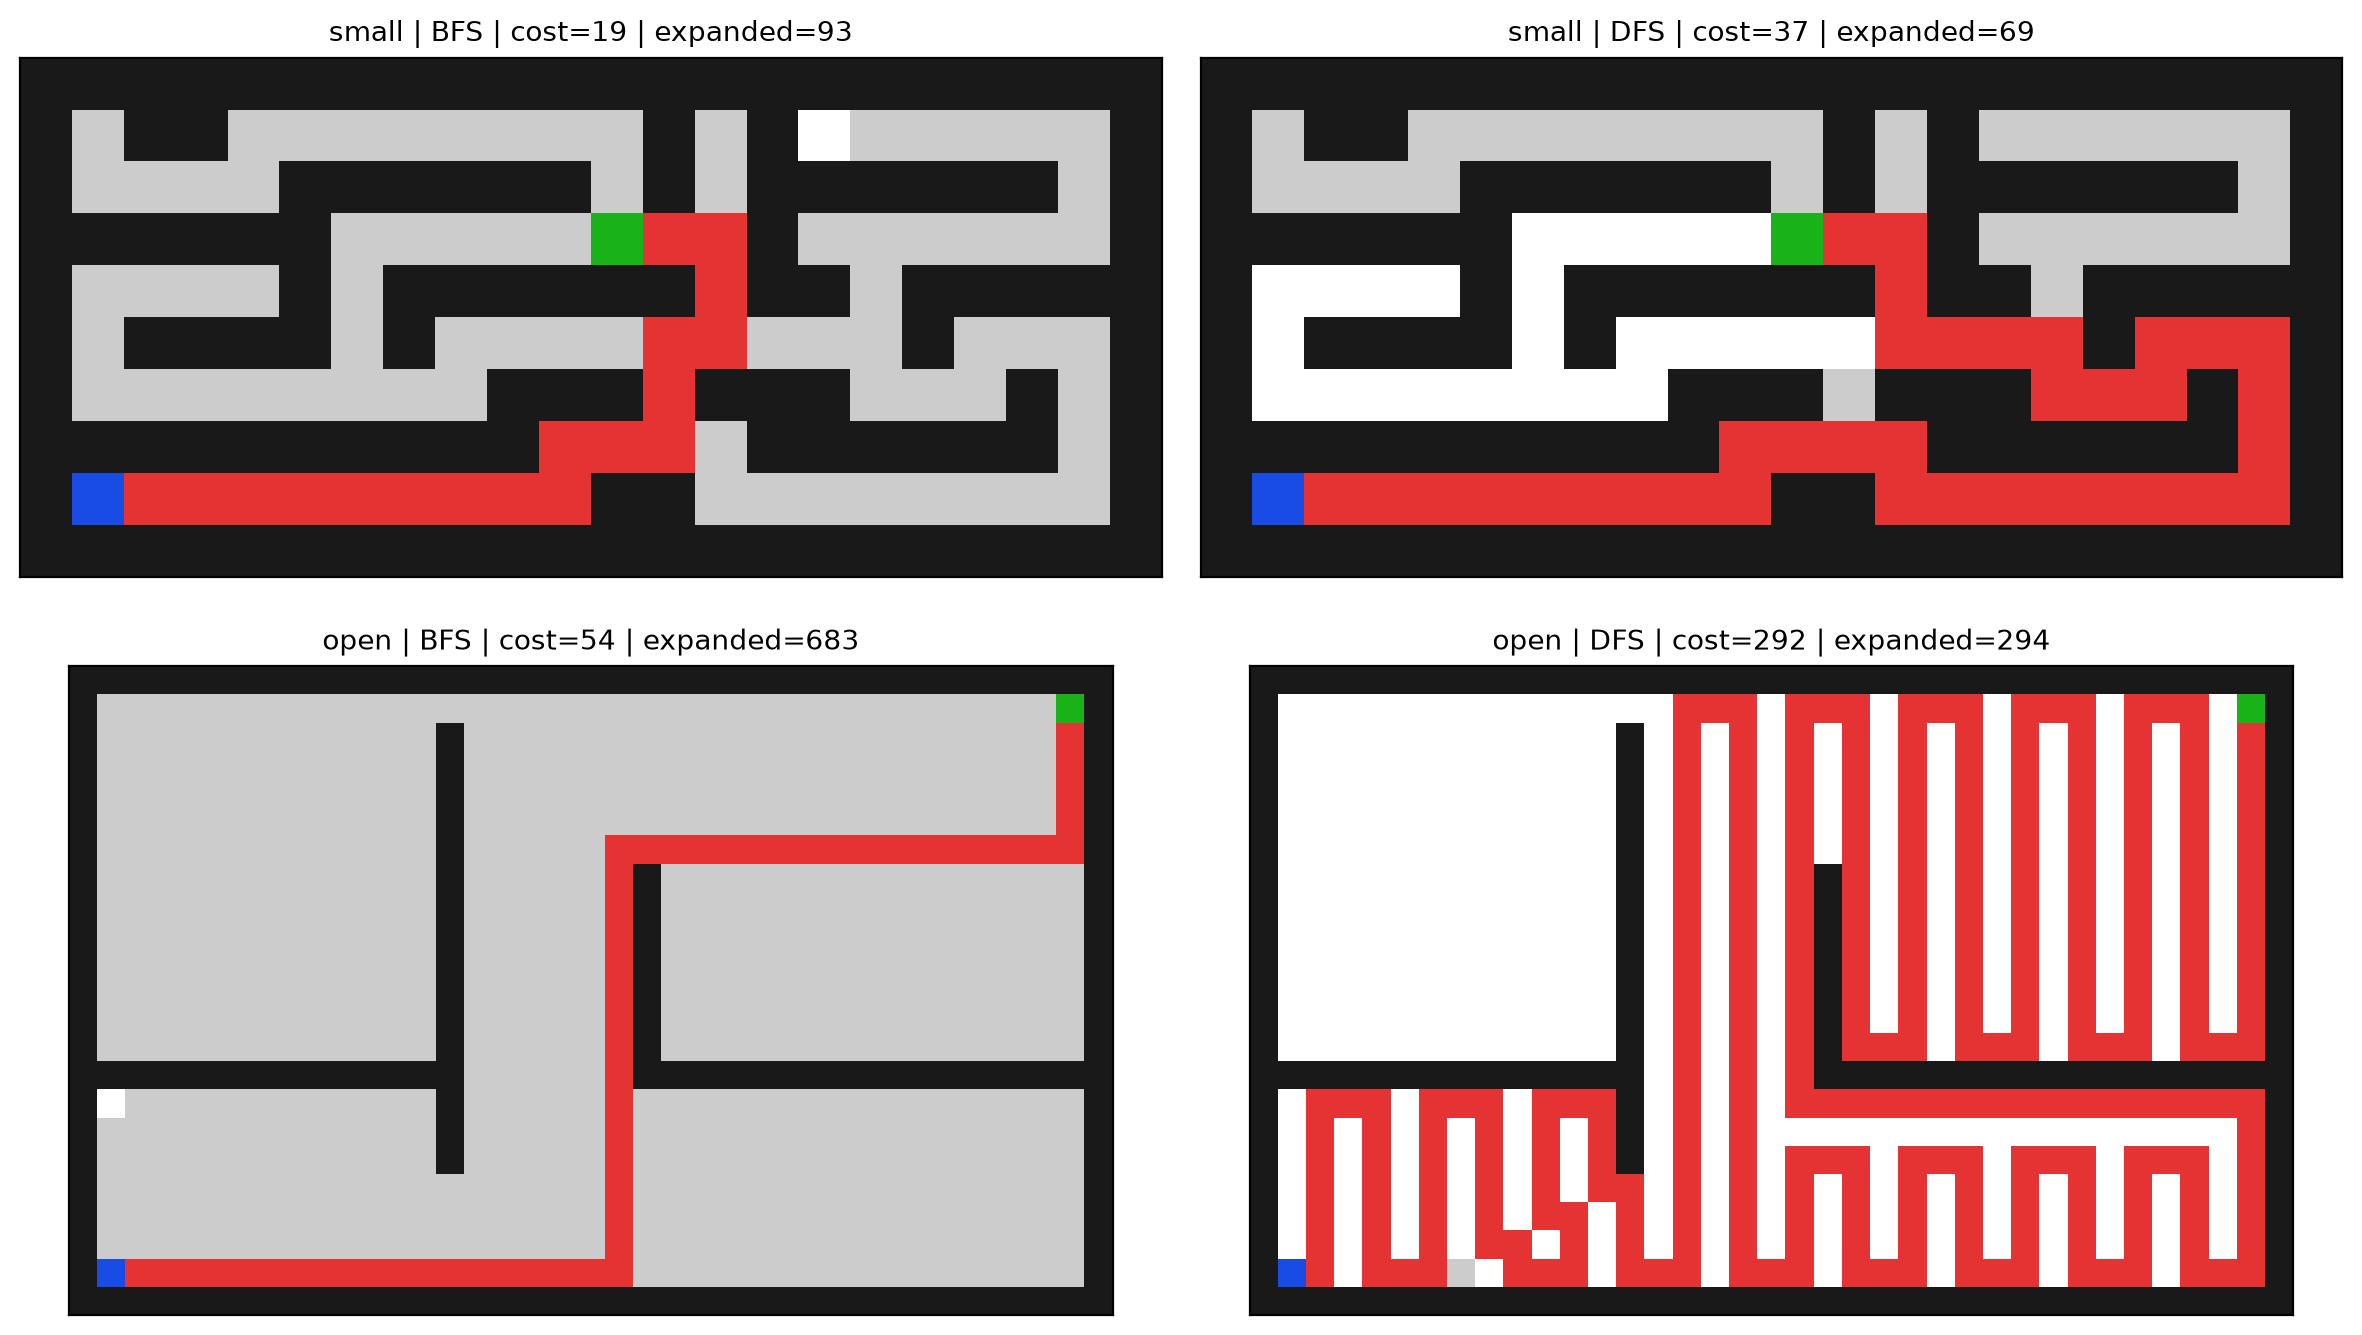

Saved lab02_bai3_bfs_dfs_paths.png


In [23]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,2,figsize=(12,7))
for i,maze_name in enumerate(['small','open']):
    for j,algorithm in enumerate(['BFS','DFS']):
        arr,res=cases[(maze_name,algorithm)]
        mh.render(arr,explored=res['explored'],path=res['path'],ax=axes[i,j],
          title=f'{maze_name} | {algorithm} | cost={res["cost"]} | expanded={res["expanded"]}')
fig.tight_layout(pad=1.4)
fig.savefig('lab02_bai3_bfs_dfs_paths.png',dpi=170,bbox_inches='tight')
display(fig);plt.close(fig)
print('Saved lab02_bai3_bfs_dfs_paths.png')

### Tính phụ thuộc vào thứ tự duyệt và ngẫu nhiên
Giữ dữ liệu small_maze, thay seed theo từng lần chạy DFS. Với giới hạn lượt mở rộng, nếu không tìm được đường trong một lần chạy thì không thể kết luận bài toán vô nghiệm.

In [24]:
import random
runs=[]
small=mh.parse_maze(Path('small_maze.txt').read_text())
for seed in range(10,18):
    random.seed(seed)
    ts.set_order('NESW',random=True)
    x=ts.DFS(small,frontier_option=2,max_tries=5000)
    runs.append({'Seed':seed,'Found':x['path'] is not None,'Cost':x['cost'],
                 'Expanded':x['expanded'],'Max frontier':x['max_frontier']})
ts.set_order('NESW',random=False)
bai3_random=pd.DataFrame(runs)
display(bai3_random)
bai3_random.to_csv('lab02_bai3_random_dfs_seeds.csv',index=False)
print('Found:',int(bai3_random.Found.sum()),'/',len(bai3_random))

,Seed,Found,Cost,Expanded,Max frontier
0,10,True,29,40,5
1,11,True,19,36,5
2,12,True,19,36,5
3,13,True,49,64,5
4,14,True,19,22,6
5,15,True,29,30,6
6,16,True,29,78,6
7,17,True,37,67,6


Found: 8 / 8


**Kết luận Bài 3:** BFS tìm đường ngắn nhất với chi phí mỗi bước bằng nhau và reached phù hợp. DFS đi sâu trước, nghiệm đầu tiên có thể dài hơn tối ưu, phụ thuộc thứ tự successor và seed. Max frontier là kích thước hàng đợi/stack quan sát được, không tương đương toàn bộ lượng bộ nhớ cần cho reached và parent. Restart Kernel → Run All để tái lập bảng, CSV và hình.